# 02. Resultados: curvas suaves y qué está contando la red

Este cuaderno no entrena nada. Lee los resultados que dejaron los scripts en `results/` y arma las tablas y figuras del proyecto. Para regenerarlos:

```
python scripts/generate_dataset.py
python scripts/smoothing_study.py
python scripts/final_runs.py
python scripts/evaluate_cross.py
python scripts/shape_baselines.py
```

Tiene tres partes:

1. por qué las curvas de validation del avance salían tan puntudas y qué las arregla;
2. la red final en los dos datasets;
3. el cruce entre datasets para ver si la red cuenta huecos o cuenta piezas.

In [1]:
import json  # para leer las métricas
import sys  # para agregar src al camino de búsqueda
from pathlib import Path  # rutas que sirven en cualquier sistema operativo

import matplotlib.pyplot as plt  # gráficos
import numpy as np  # arreglos numéricos
import pandas as pd  # tablas

ROOT = Path.cwd().parent  # carpeta raíz del repositorio (este cuaderno vive en notebooks/)
sys.path.insert(0, str(ROOT / "src"))  # permite importar genuscnn sin instalarlo

from genuscnn.plots import plot_before_after, plot_confusion, plot_history, plot_study  # figuras del proyecto

RESULTS = ROOT / "results"  # carpeta de resultados


def load_run(folder):  # lee el historial y las métricas de una corrida
    history = pd.read_csv(folder / "history.csv")  # historial por época
    metrics = json.loads((folder / "metrics.json").read_text())  # métricas finales
    return history, metrics  # devuelve las dos cosas

## 1. El problema: la validation del avance

Esta es la red del avance (`configs/base.yaml`): la misma arquitectura, AdamW con tasa de aprendizaje fija 0.001, BatchNorm, dropout 0.3 y 50 épocas. La curva de train es suave, pero la de validation salta de una época a la siguiente.

Para ponerle un número a "puntuda" se usa la **rugosidad**: el promedio del salto absoluto entre épocas seguidas, desde la época 6. Una rugosidad de 0.12 en accuracy quiere decir que de una época a la otra la accuracy de validation cambia 12 puntos en promedio.

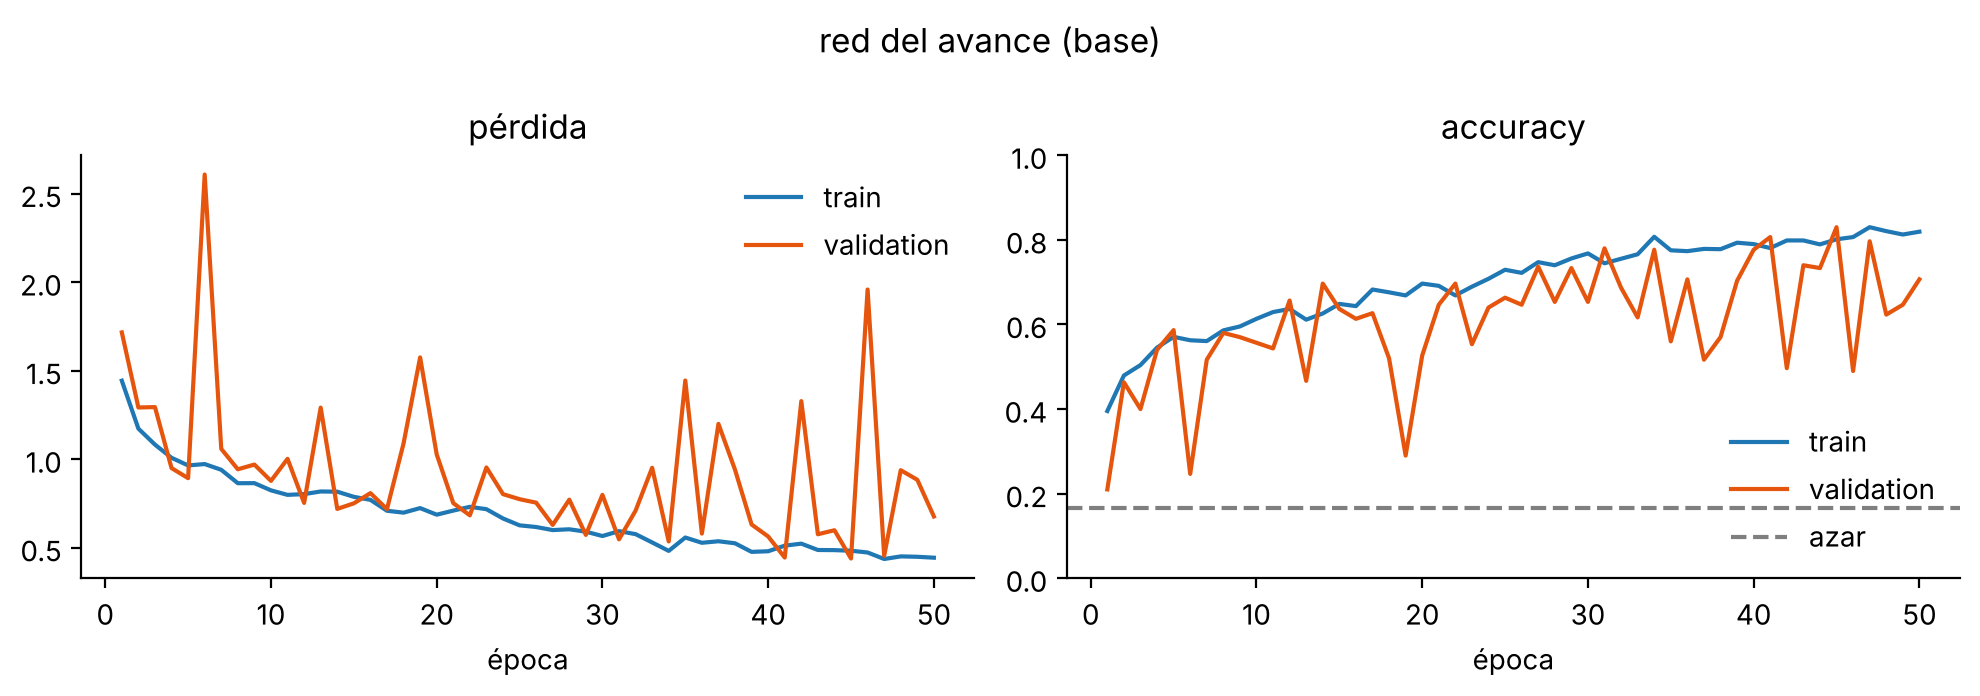

rugosidad de la accuracy de validation: 0.118
rugosidad de la pérdida de validation: 0.367
peor accuracy de validation después de la época 10: 0.29


In [2]:
base_history, base_metrics = load_run(RESULTS / "smoothing" / "base")  # red del avance
plot_history(base_history, "red del avance (base)")  # curvas de pérdida y accuracy
plt.show()  # muestra la figura
print("rugosidad de la accuracy de validation:", round(base_metrics["roughness_val_acc"], 3))  # salto medio entre épocas
print("rugosidad de la pérdida de validation:", round(base_metrics["roughness_val_loss"], 3))  # salto medio de la pérdida
print("peor accuracy de validation después de la época 10:", round(base_metrics["worst_val_acc_after_10"], 3))  # peor caída

## 2. Qué se probó para suavizarla

Cada experimento cambia **una sola cosa** frente a la red base, con el mismo dataset (`cadena`), el mismo split y la misma semilla. Los últimos combinan las que funcionaron.

Sobre backpropagation: la red del avance ya entrenaba con backpropagation. Es el `loss.backward()` del ciclo de entrenamiento, que calcula los gradientes, y no hay forma de entrenar esta red sin él: el control `sin_backprop` lo muestra, con una curva plana pegada al azar. Lo que sí se puede cambiar es qué se hace con esos gradientes, y eso es lo que prueban estos experimentos.

| experimento | qué cambia | idea |
|---|---|---|
| `sin_backprop` | backpropagation apagada | control: sin gradientes los pesos nunca cambian y la red se queda en el azar |
| `dropout_05` | dropout 0.3 → 0.5 | más regularización |
| `lr_baja` | tasa fija 0.001 → 0.0003 | pasos más cortos |
| `val_3_vistas` | 3 vistas por superficie en validation | descartar que el salto sea ruido por tener pocas imágenes |
| `coseno` | la tasa sube 3 épocas y luego baja en coseno hasta cero | pasos grandes al principio y cortos al final |
| `ema` | se evalúa un promedio móvil de los pesos | el promedio de los últimos pasos es más estable que el último paso |
| `groupnorm` | GroupNorm en lugar de BatchNorm | quitar las estadísticas de BatchNorm, que en evaluación son distintas a las de train |
| `bn_lenta` | BatchNorm con momentum 0.01 | que las estadísticas de BatchNorm recuerden más batches |
| `coseno_ema` | coseno y promedio móvil | las dos mejores juntas |
| `suave` | coseno, promedio móvil, 3 vistas, suavizado de etiquetas 0.05 y recorte de gradiente | receta completa |
| `suave_100` | la receta completa con 100 épocas | ver si entrenar más ayuda |

In [3]:
study = pd.read_csv(RESULTS / "smoothing" / "summary.csv")  # tabla del estudio
study.sort_values("rugosidad_val_acc", ascending=False).reset_index(drop=True)  # de la más puntuda a la más suave

,experimento,rugosidad_val_acc,rugosidad_val_loss,peor_val_acc,mejor_epoca,val_acc,test_acc,test_acc_voto
0,bn_lenta,0.142,0.792,0.173,43,0.777,0.799,0.870
1,dropout_05,0.126,0.369,0.237,49,0.833,0.829,0.927
2,val_3_vistas,0.118,0.367,0.313,41,0.812,0.826,0.923
3,base,0.118,0.367,0.290,45,0.830,0.803,0.910
4,lr_baja,0.099,0.186,0.427,45,0.823,0.819,0.913
5,coseno,0.072,0.235,0.303,48,0.853,0.843,0.950
6,groupnorm,0.040,0.071,0.483,44,0.790,0.802,0.913
7,ema,0.023,0.031,0.613,50,0.827,0.831,0.927
8,coseno_ema,0.018,0.029,0.487,50,0.853,0.843,0.947
9,suave,0.013,0.028,0.600,50,0.838,0.862,0.950


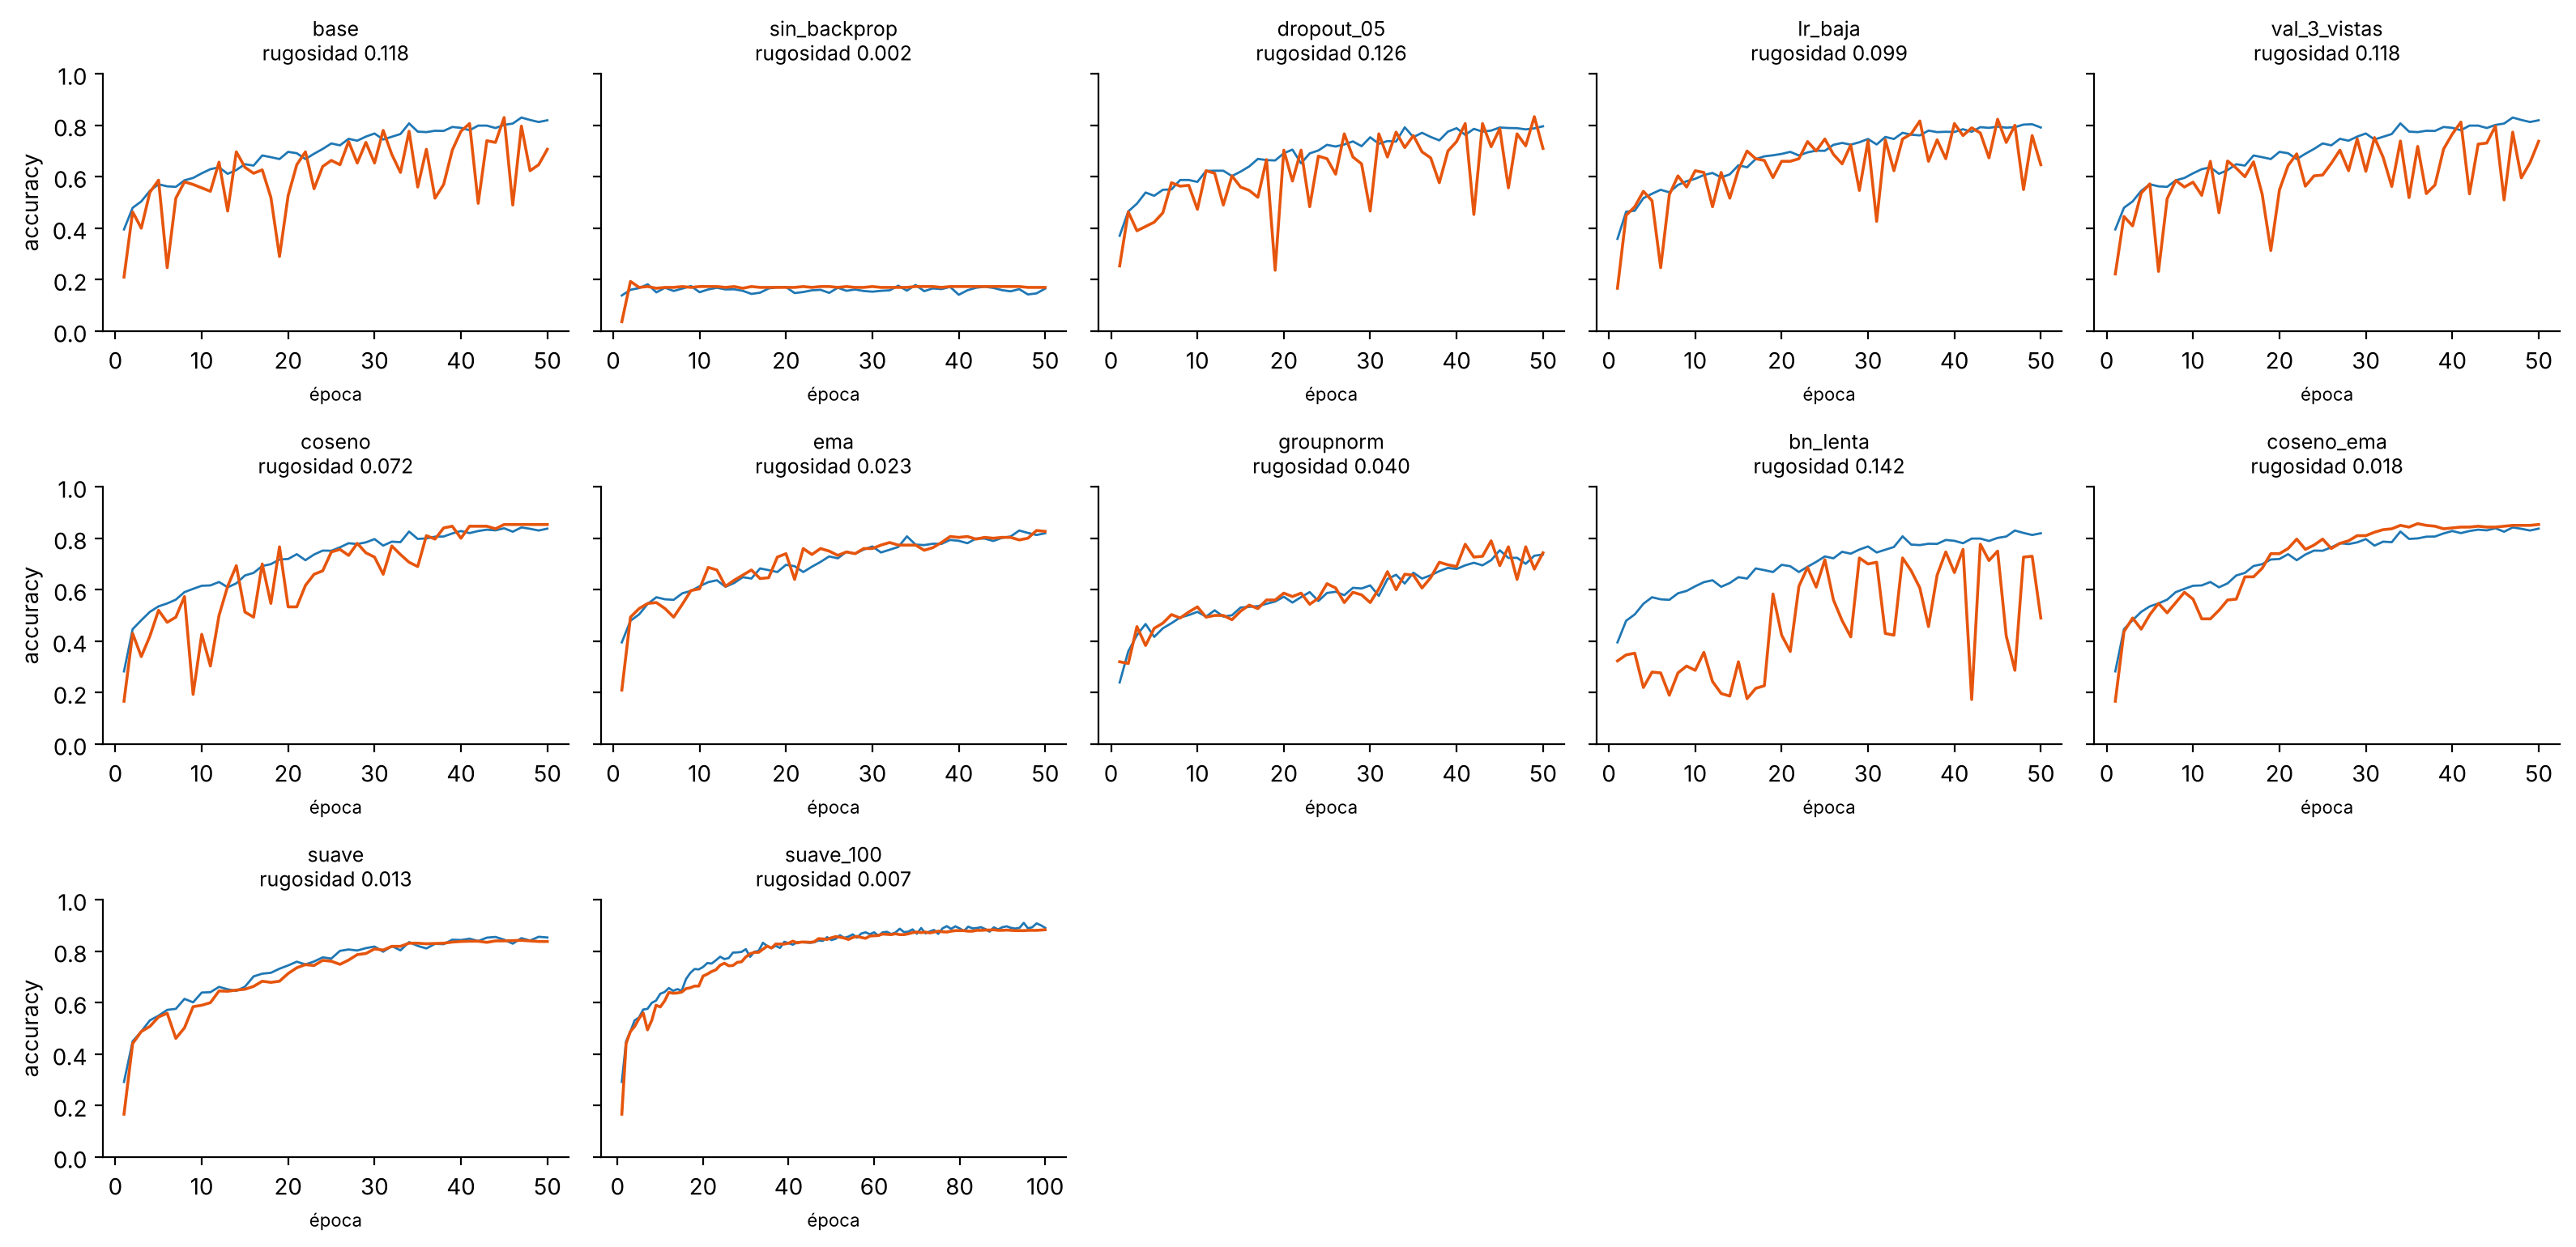

In [4]:
histories = {name: pd.read_csv(RESULTS / "smoothing" / name / "history.csv") for name in study["experimento"]}  # historial de cada experimento
plot_study(histories, study)  # una curva por experimento (azul = train, naranja = validation)
plt.show()  # muestra la figura

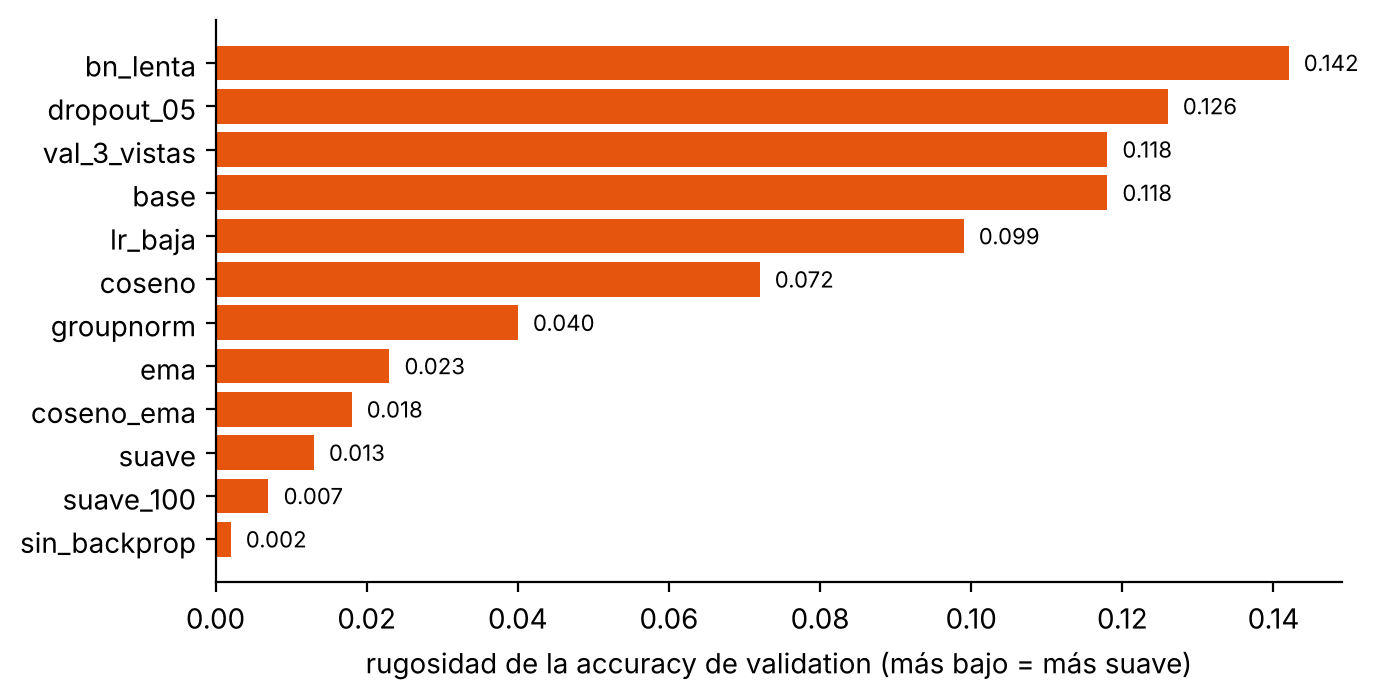

In [5]:
order = study.sort_values("rugosidad_val_acc")  # experimentos de la curva más suave a la más puntuda
fig, ax = plt.subplots(figsize=(7, 3.6))  # figura de barras
ax.barh(order["experimento"], order["rugosidad_val_acc"], color="#e6550d")  # una barra por experimento
for y, value in enumerate(order["rugosidad_val_acc"]):  # recorre las barras
    ax.text(value + 0.002, y, f"{value:.3f}", va="center", fontsize=8)  # escribe el valor al lado
ax.set_xlabel("rugosidad de la accuracy de validation (más bajo = más suave)")  # nombre del eje x
ax.spines[["top", "right"]].set_visible(False)  # quita los bordes de arriba y de la derecha
plt.tight_layout()  # ajusta los espacios
plt.show()  # muestra la figura

## 3. Antes y después

A la izquierda la red del avance y a la derecha la receta final (`configs/suave.yaml`), las dos sobre el dataset `cadena`.

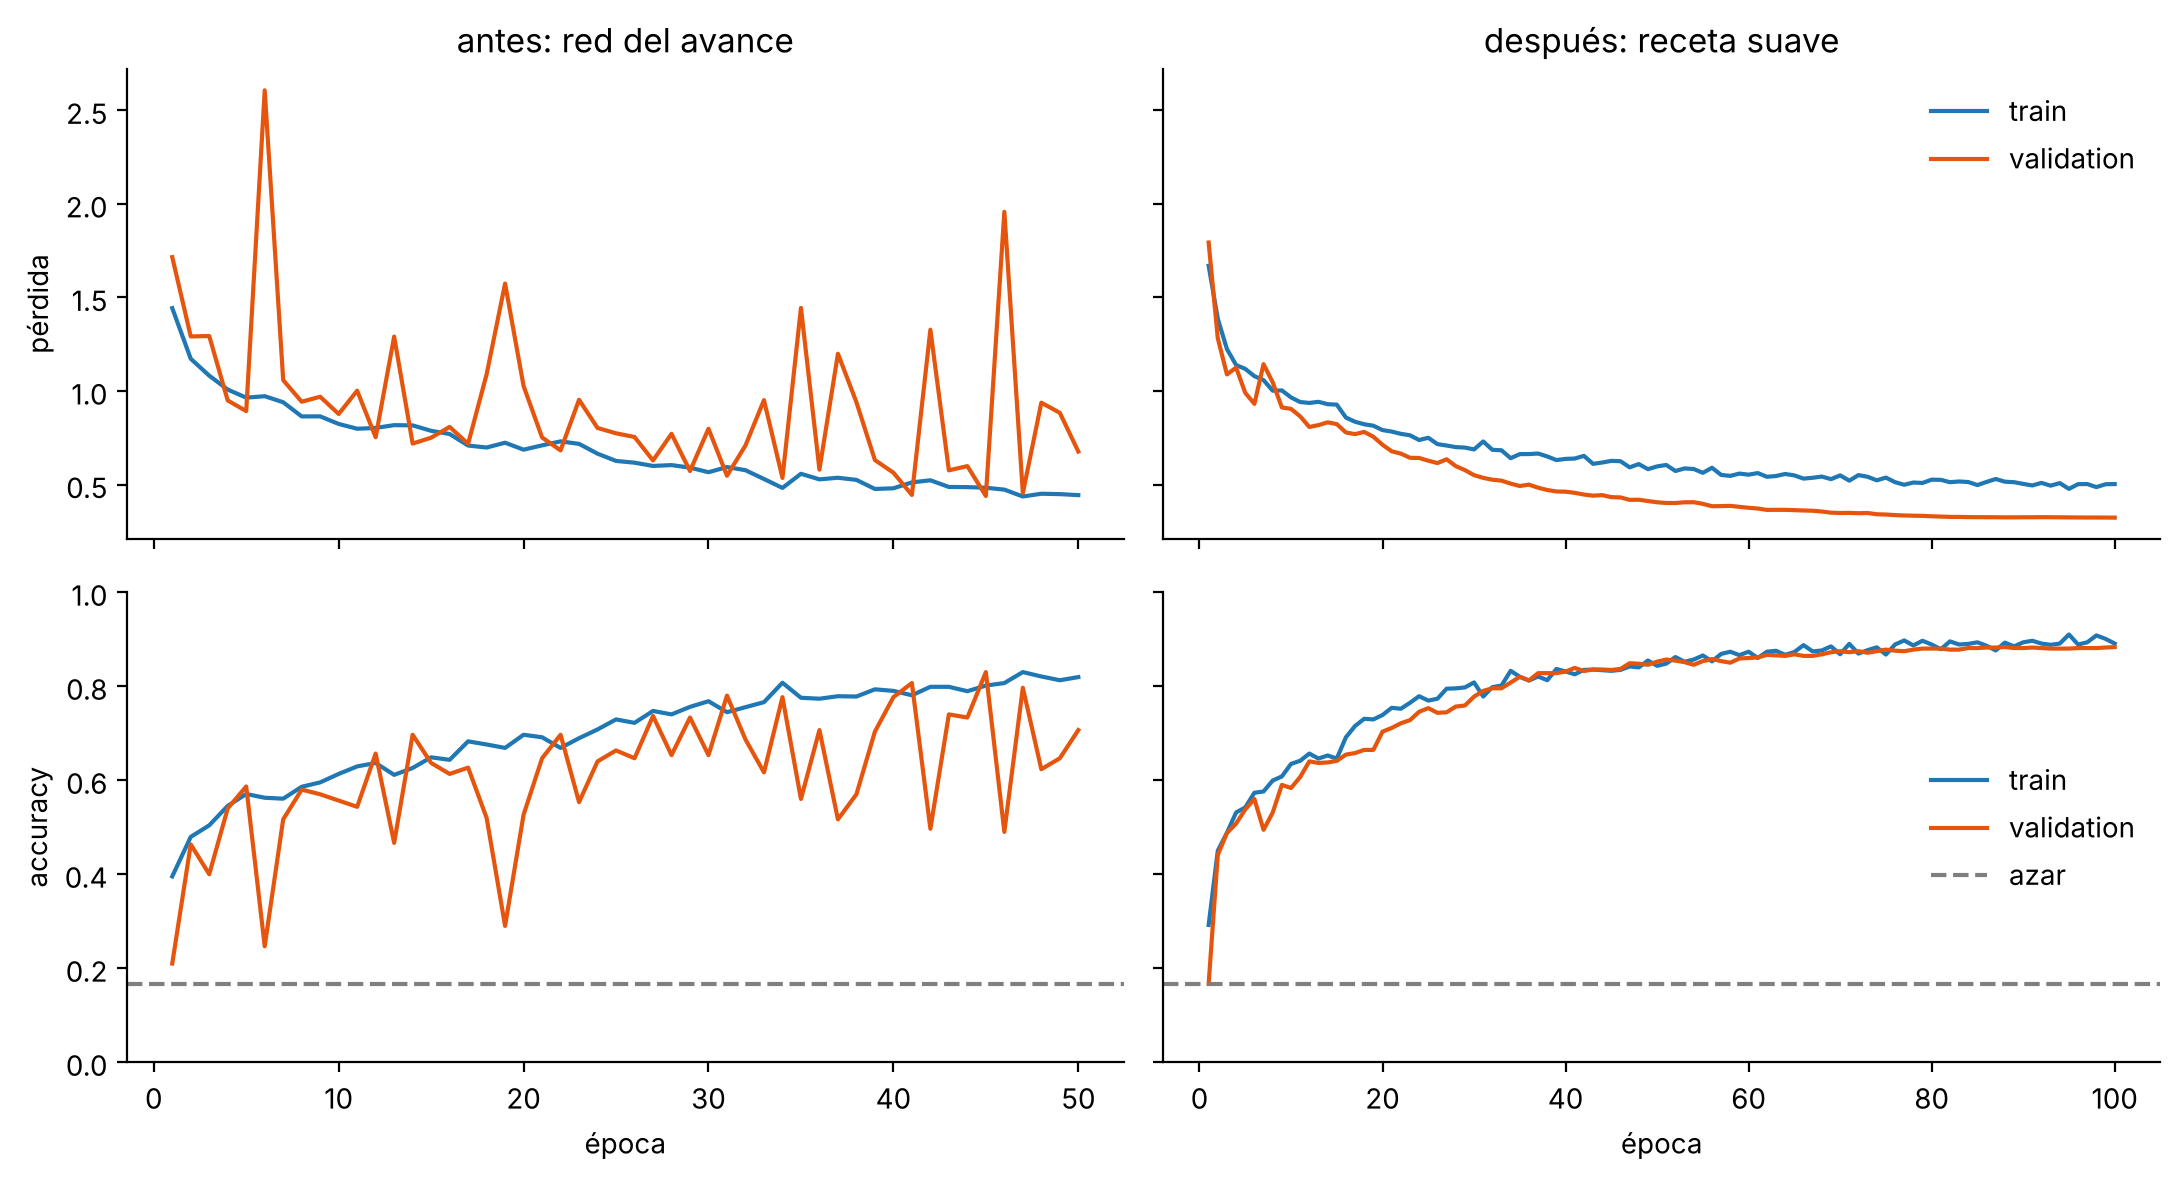

,antes,después
rugosidad accuracy val,0.118,0.007
rugosidad pérdida val,0.367,0.013
peor accuracy val tras época 10,0.290,0.607
accuracy test por imagen,0.803,0.904
accuracy test por superficie,0.910,0.973


In [6]:
final_history, final_metrics = load_run(RESULTS / "runs" / "suave_cadena")  # red final sobre cadena
plot_before_after(base_history, final_history, ("antes: red del avance", "después: receta suave"))  # compara las curvas
plt.show()  # muestra la figura
comparison = pd.DataFrame({  # tabla de antes y después
    "antes": [base_metrics["roughness_val_acc"], base_metrics["roughness_val_loss"], base_metrics["worst_val_acc_after_10"], base_metrics["test"]["accuracy"], base_metrics["test_vote"]["accuracy"]],  # red del avance
    "después": [final_metrics["roughness_val_acc"], final_metrics["roughness_val_loss"], final_metrics["worst_val_acc_after_10"], final_metrics["test"]["accuracy"], final_metrics["test_vote"]["accuracy"]],  # red final
}, index=["rugosidad accuracy val", "rugosidad pérdida val", "peor accuracy val tras época 10", "accuracy test por imagen", "accuracy test por superficie"])  # nombre de cada fila
comparison.round(3)  # muestra la tabla

## 4. La red final en los dos datasets

Se entrena la misma receta en `cadena` y en `conexa`, con tres semillas cada una. Para cada corrida se reporta:

- **azar:** 1/6;
- **tinta:** una regresión logística que solo ve la proporción de píxeles pintados;
- **cnn por imagen:** accuracy sobre las 900 imágenes de test (300 superficies, 3 vistas cada una);
- **cnn por superficie:** se promedian las salidas de las 3 vistas de cada superficie antes de decidir.

Las familias de test nunca se vieron en train ni se usaron para elegir la época.

In [7]:
rows = []  # filas de la tabla
for folder in sorted((RESULTS / "runs").glob("*")):  # recorre todas las corridas finales
    if not (folder / "metrics.json").exists():  # si la corrida no terminó
        continue  # la salta
    _, m = load_run(folder)  # métricas de la corrida
    cfg = json.loads((folder / "config.json").read_text())  # configuración de la corrida
    recipe = "avance" if folder.name.startswith("base") else "suave"  # qué receta usó
    rows.append(dict(corrida=folder.name, receta=recipe, dataset=cfg["variant"], semilla=cfg["seed"], azar=m["chance"], tinta=m["ink_test"]["accuracy"], cnn_imagen=m["test"]["accuracy"], cnn_superficie=m["test_vote"]["accuracy"], macro_f1=m["test"]["macro_f1"], rugosidad=m["roughness_val_acc"]))  # fila
runs = pd.DataFrame(rows)  # tabla de corridas
runs.round(3)  # muestra la tabla

,corrida,receta,dataset,semilla,azar,tinta,cnn_imagen,cnn_superficie,macro_f1,rugosidad
0,base_conexa,avance,conexa,11,0.167,0.356,0.813,0.913,0.811,0.114
1,suave_cadena,suave,cadena,11,0.167,0.394,0.904,0.973,0.903,0.007
2,suave_cadena_s12,suave,cadena,12,0.167,0.401,0.906,0.973,0.904,0.011
3,suave_cadena_s13,suave,cadena,13,0.167,0.396,0.899,0.977,0.898,0.007
4,suave_conexa,suave,conexa,11,0.167,0.356,0.879,0.963,0.878,0.014
5,suave_conexa_s12,suave,conexa,12,0.167,0.354,0.893,0.977,0.893,0.013
6,suave_conexa_s13,suave,conexa,13,0.167,0.356,0.891,0.973,0.891,0.012


In [8]:
summary = runs[runs["receta"] == "suave"].groupby("dataset")[["tinta", "cnn_imagen", "cnn_superficie", "macro_f1", "rugosidad"]].agg(["mean", "std"])  # media y desviación entre semillas
summary.round(3)  # muestra la tabla

tinta        cnn_imagen        cnn_superficie        macro_f1         \
          mean    std       mean    std           mean    std     mean    std   
dataset                                                                         
cadena   0.397  0.004      0.903  0.004          0.974  0.002    0.902  0.003   
conexa   0.355  0.001      0.888  0.008          0.971  0.007    0.887  0.008   

        rugosidad         
             mean    std  
dataset                   
cadena      0.008  0.002  
conexa      0.013  0.001

cadena recall por género: [1.0, 0.9867, 0.9533, 0.8533, 0.7267, 0.9067] | errores a distancia 1: 73 de 86
conexa recall por género: [0.9867, 0.98, 0.9267, 0.7733, 0.7467, 0.86] | errores a distancia 1: 101 de 109


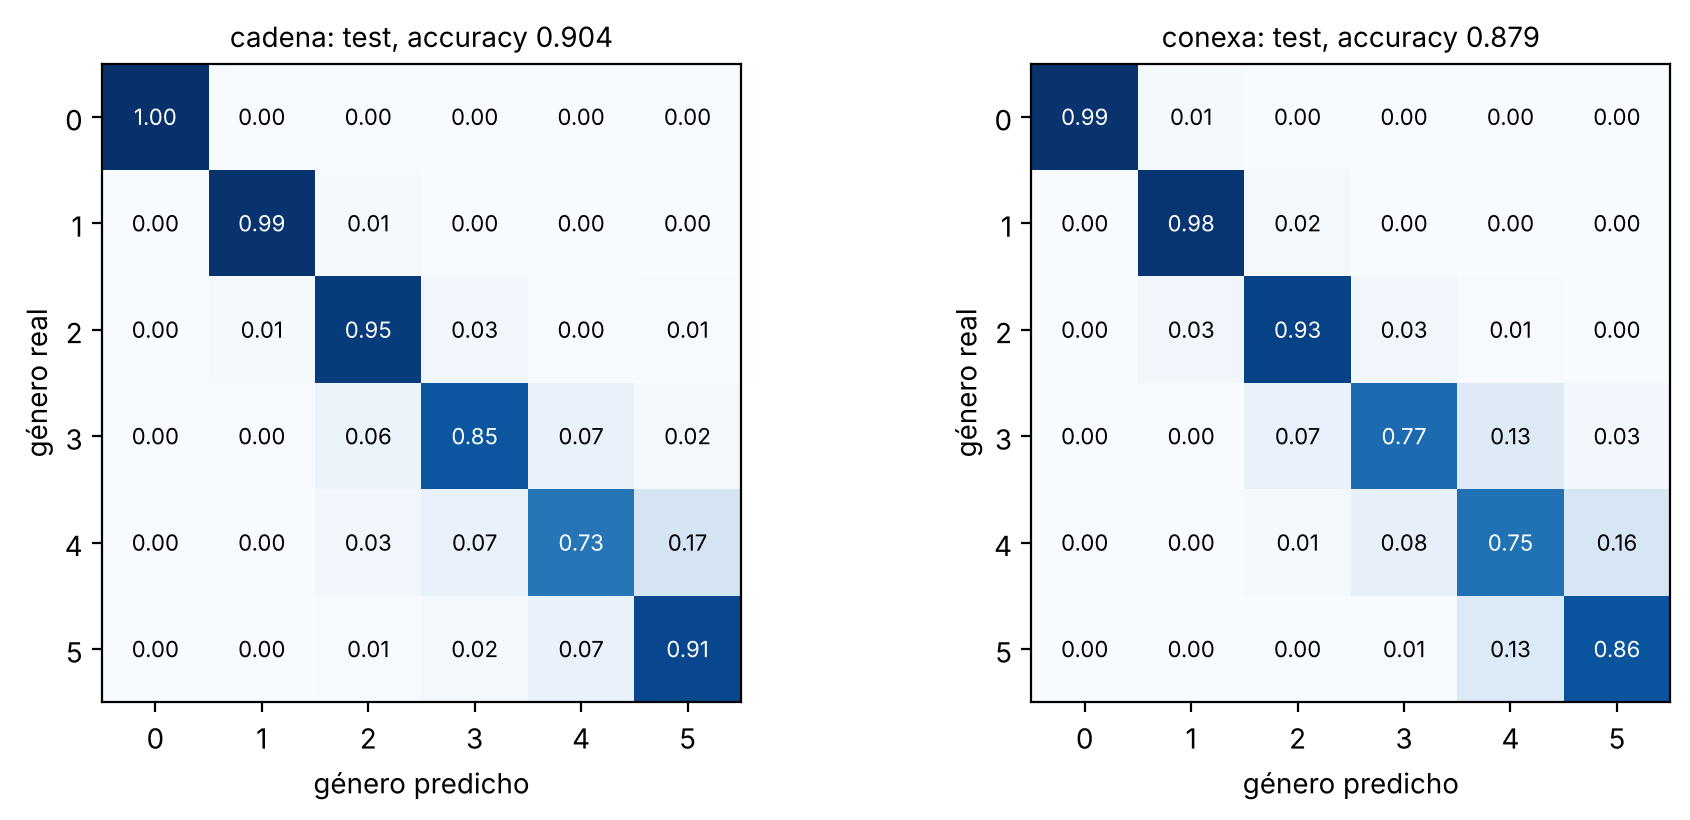

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))  # una matriz de confusión por dataset
for ax, variant in zip(axes, ("cadena", "conexa")):  # recorre los dos datasets
    _, m = load_run(RESULTS / "runs" / f"suave_{variant}")  # red final de ese dataset
    plot_confusion(m["test"]["confusion"], f"{variant}: test, accuracy {m['test']['accuracy']:.3f}", ax)  # matriz de test
    print(variant, "recall por género:", m["test"]["recall"], "| errores a distancia 1:", m["test"]["errors_distance_1"], "de", m["test"]["errors"])  # detalle de los errores
plt.tight_layout()  # ajusta los espacios
plt.show()  # muestra la figura

## 5. ¿La red cuenta huecos o cuenta piezas?

En `cadena` hay dos maneras de acertar la etiqueta: contar huecos o contar piezas sueltas, porque coinciden. En `conexa` solo sirve contar huecos, porque siempre hay una pieza. Entonces se cruza: cada red final se evalúa en el test del otro dataset, sin reentrenar.

- Si la red de `cadena` aprendió a contar huecos, debería seguir acertando en `conexa`.
- Si aprendió a contar piezas, en `conexa` debería fallar, porque todo le parecería una sola pieza.

In [10]:
cross = pd.read_csv(RESULTS / "cross" / "summary.csv")  # tabla del cruce, una fila por red y dataset de evaluación
cross.groupby(["entrenada_en", "evaluada_en"])[["test_acc", "test_acc_voto", "distancia_media", "sesgo"]].agg(["mean", "std"]).round(3)  # media y desviación entre semillas

test_acc        test_acc_voto        distancia_media  \
                             mean    std          mean    std            mean   
entrenada_en evaluada_en                                                        
cadena       cadena         0.903  0.004         0.974  0.002           0.115   
             conexa         0.819  0.009         0.912  0.015           0.208   
conexa       cadena         0.762  0.006         0.830  0.003           0.285   
             conexa         0.888  0.008         0.971  0.007           0.126   

                                 sesgo         
                            std   mean    std  
entrenada_en evaluada_en                       
cadena       cadena       0.006  0.002  0.002  
             conexa       0.009 -0.140  0.010  
conexa       cadena       0.004  0.204  0.009  
             conexa       0.004  0.006  0.007

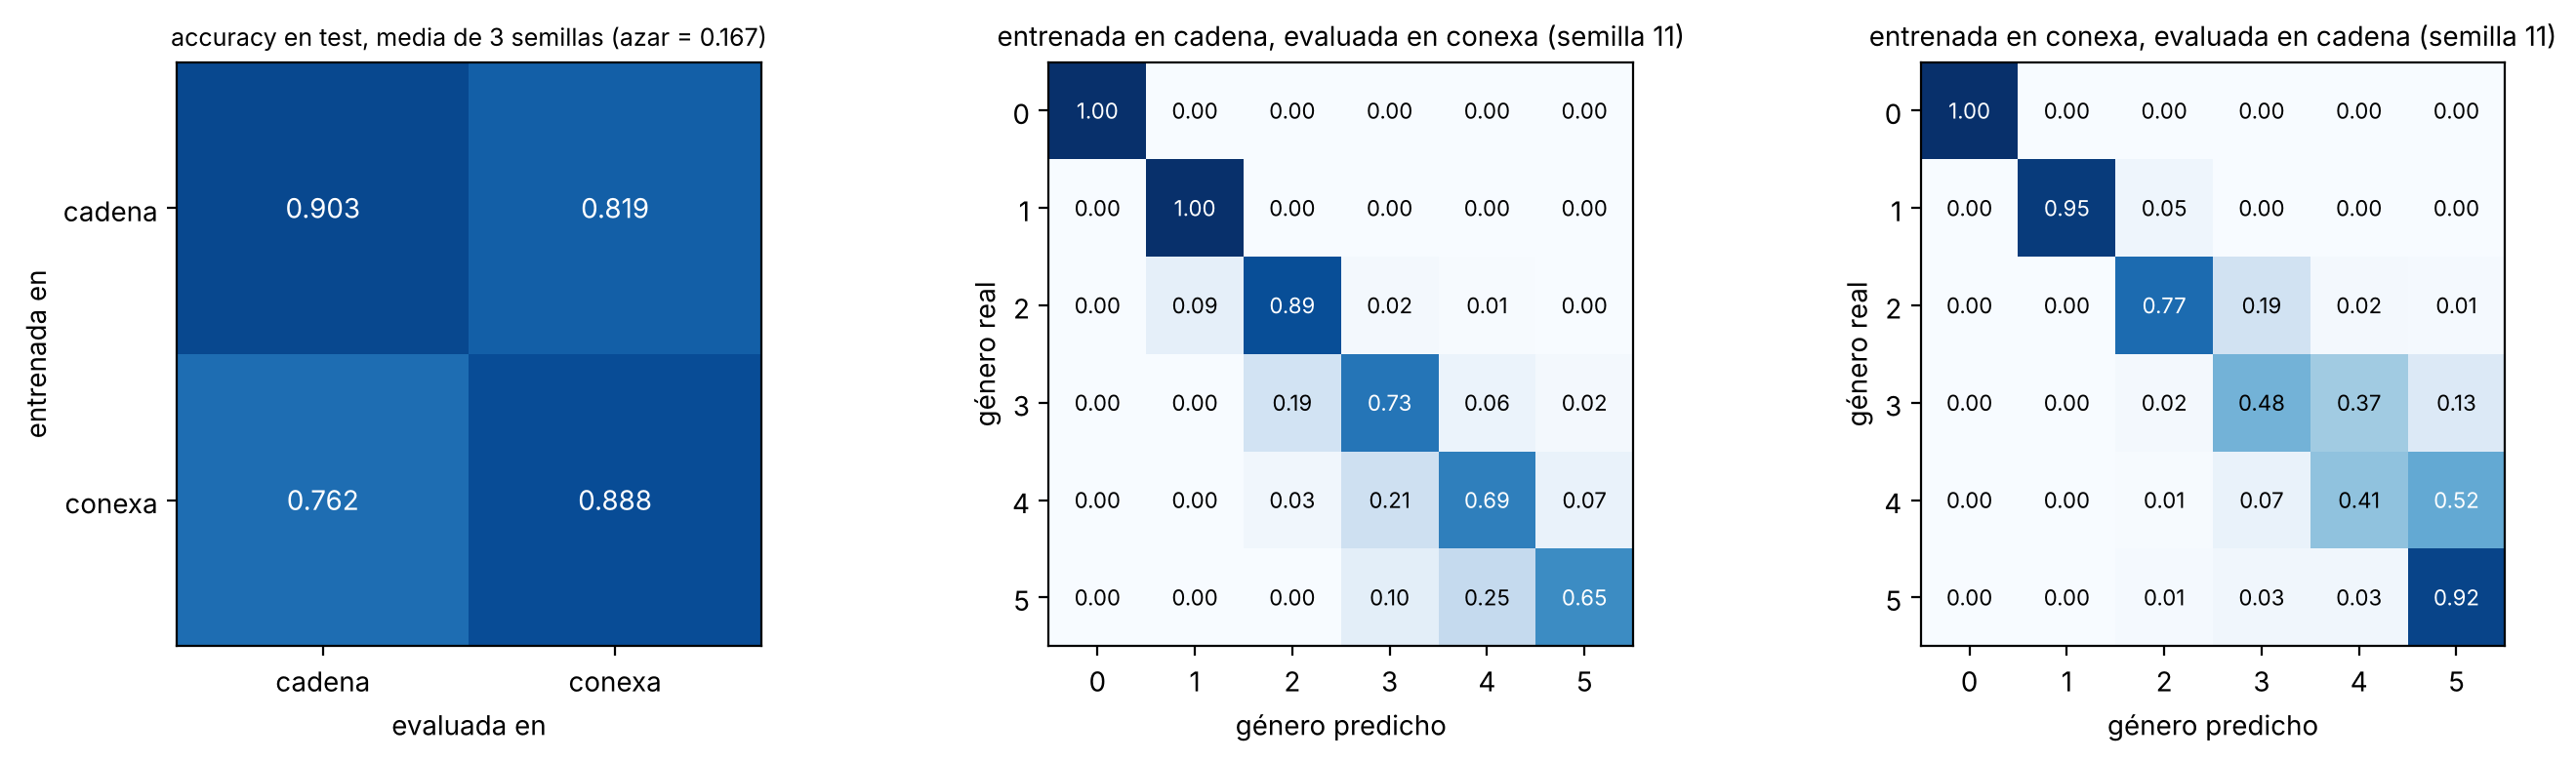

In [11]:
grid = cross.groupby(["entrenada_en", "evaluada_en"])["test_acc"].mean().unstack()  # media entre semillas: filas = entrenamiento, columnas = evaluación
details = json.loads((RESULTS / "cross" / "details.json").read_text())  # métricas completas del cruce
fig, axes = plt.subplots(1, 3, figsize=(14, 4))  # cruce y las dos matrices cruzadas
axes[0].imshow(grid.values, cmap="Blues", vmin=0, vmax=1)  # mapa de calor del cruce
axes[0].set_xticks(range(2), grid.columns)  # nombres de las columnas
axes[0].set_yticks(range(2), grid.index)  # nombres de las filas
axes[0].set_xlabel("evaluada en")  # nombre del eje x
axes[0].set_ylabel("entrenada en")  # nombre del eje y
axes[0].set_title("accuracy en test, media de 3 semillas (azar = 0.167)", fontsize=9)  # título
for i in range(2):  # recorre las filas
    for j in range(2):  # recorre las columnas
        axes[0].text(j, i, f"{grid.values[i, j]:.3f}", ha="center", va="center", color="white" if grid.values[i, j] > 0.5 else "black")  # valor de la casilla
plot_confusion(details["suave_cadena->conexa"]["test"]["confusion"], "entrenada en cadena, evaluada en conexa (semilla 11)", axes[1])  # matriz cruzada
plot_confusion(details["suave_conexa->cadena"]["test"]["confusion"], "entrenada en conexa, evaluada en cadena (semilla 11)", axes[2])  # matriz cruzada
plt.tight_layout()  # ajusta los espacios
plt.show()  # muestra la figura

## Conclusiones

**Sobre las curvas.** La validation del avance no era puntuda por tener pocas imágenes ni por falta de dropout: triplicar las vistas de validation o subir el dropout dejó la rugosidad igual. Lo que la calma es evaluar un promedio móvil de los pesos (rugosidad 0.023) y bajar la tasa de aprendizaje con un coseno. Cambiar BatchNorm por GroupNorm también la suaviza (0.040) y darle más memoria a BatchNorm la empeora (0.142), lo que apunta a que en evaluación las estadísticas guardadas de BatchNorm quedaban desactualizadas frente a unos pesos que cambiaban rápido. Con la receta final la rugosidad pasa de 0.118 a 0.007 y la accuracy en test de 0.803 a 0.904.

**Sobre la red final.** Con tres semillas, la accuracy en test por imagen es 0.903 ± 0.004 en `cadena` y 0.888 ± 0.008 en `conexa`; juntando las tres vistas de cada superficie sube a 0.974 ± 0.002 y 0.971 ± 0.007. La línea base de la silueta, que ve la tinta y la forma de la mancha pero ningún hueco, se queda en 0.462 y 0.427. Los errores se concentran en los géneros 3, 4 y 5 (el 4 es el más difícil) y más de 8 de cada 10 son por un solo género.

**Sobre qué cuenta la red.** Una red que solo vio toros sueltos acierta 0.819 en superficies conexas que nunca vio, lejos del azar (0.167). Si contara piezas, ahí todo le parecería género 0 o 1. Lo que aprendió se parece más a contar huecos. La transferencia no es perfecta y tiene dirección: de `cadena` a `conexa` predice géneros de menos (sesgo -0.14) y de `conexa` a `cadena` predice de más (sesgo +0.20).

**Lo que falta.** Todas las superficies son cadenas rectas de toros y el largo crece con el género. El cruce descarta el atajo de contar piezas, no todos los atajos. El siguiente paso es probar superficies de género g con otras formas, o volver a EuLearn con esta receta de entrenamiento.